# Практика 5. Вариант 5
## Агрегаты по пользователю, мин–макс нормализация и поиск максимумов

**Цель:** построить агрегированные признаки по каждому пользователю
(заказы, выручка, события), нормализовать их методом min–max и найти
пользователей-лидеров по каждому признаку.

**Задачи:**
1. Построить агрегаты по пользователю: `orders_count`, `revenue_sum`, `events_count`.
2. Применить мин–макс нормализацию к этим признакам.
3. Найти пользователей с максимальными нормализованными значениями
   для каждого признака.

In [1]:
import pandas as pd
import numpy as np
import os

# ============================================================
# ГЕНЕРАТОР ТЕСТОВЫХ ДАННЫХ
# ============================================================
os.makedirs("data", exist_ok=True)
np.random.seed(42)

# --- Заказы (3 CSV) ---
def make_orders(n, start_date):
    return pd.DataFrame({
        "order_id":       range(1, n + 1),
        "user_id":        np.random.randint(1, 150, n),
        "order_datetime": pd.date_range(start_date, periods=n, freq="3h"),
        "product_id":     np.random.randint(101, 121, n),
        "price":          np.random.uniform(100, 5000, n).round(2),
        "quantity":       np.random.randint(1, 6, n),
        "status":         np.random.choice(
            ["paid", "cancelled", "refunded"], n, p=[0.85, 0.10, 0.05]),
    })

make_orders(400, "2024-01-01").to_csv("data/orders_2024_01.csv", index=False)
make_orders(400, "2024-02-01").to_csv("data/orders_2024_02.csv", index=False)
make_orders(500, "2024-03-01").to_csv("data/orders_2024_03.csv", index=False)

# --- События (JSON Lines) ---
event_types = ["page_view", "click", "scroll", "add_to_cart", "purchase"]
pages = ["/", "/catalog", "/product/101", "/cart", "/checkout"]

events = []
event_id = 1
for user_id in range(1, 151):
    n_events = np.random.randint(0, 60)   # у части пользователей 0 событий
    base_time = pd.Timestamp("2024-01-01") + pd.Timedelta(
        hours=int(np.random.randint(0, 24 * 60)))
    for i in range(n_events):
        events.append({
            "event_id":   event_id,
            "user_id":    user_id,
            "event_time": (base_time + pd.Timedelta(minutes=i * 3)).isoformat(),
            "event_type": np.random.choice(event_types,
                                           p=[0.5, 0.25, 0.1, 0.1, 0.05]),
            "page":       np.random.choice(pages),
        })
        event_id += 1

pd.DataFrame(events).to_json("data/events_lines.json",
                             orient="records", lines=True, force_ascii=False)
pd.DataFrame(columns=["event_id", "user_id", "event_time",
                      "event_type", "page"]).to_json(
    "data/events_records.json", orient="records", force_ascii=False)

print("✅ Файлы созданы:")
print("   data/orders_2024_01.csv")
print("   data/orders_2024_02.csv")
print("   data/orders_2024_03.csv")
print("   data/events_lines.json")
print("   data/events_records.json")
print(f"   всего событий: {len(events)}")

✅ Файлы созданы:
   data/orders_2024_01.csv
   data/orders_2024_02.csv
   data/orders_2024_03.csv
   data/events_lines.json
   data/events_records.json
   всего событий: 3996


## 1. Загрузка и подготовка данных

Читаем все CSV с заказами, объединяем в один DataFrame.
Считаем `revenue = price × quantity`. Затем читаем события из JSON
и объединяем оба файла в один DataFrame.

In [2]:
orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]

df_orders = pd.concat(
    [pd.read_csv(f, parse_dates=["order_datetime"]) for f in orders_files],
    ignore_index=True
)
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]

print("Заказы:", df_orders.shape)
print(df_orders.head())

Заказы: (1300, 8)
   order_id  user_id      order_datetime  product_id    price  quantity  \
0         1      103 2024-01-01 00:00:00         113  4877.83         5   
1         2       93 2024-01-01 03:00:00         104  2504.67         3   
2         3       15 2024-01-01 06:00:00         116  3642.19         4   
3         4      107 2024-01-01 09:00:00         116  4122.22         3   
4         5       72 2024-01-01 12:00:00         102  3620.44         5   

      status   revenue  
0       paid  24389.15  
1       paid   7514.01  
2       paid  14568.76  
3       paid  12366.66  
4  cancelled  18102.20  


In [3]:
df_events_records = pd.read_json("data/events_records.json", orient="records")
df_events_lines = pd.read_json("data/events_lines.json", lines=True)

df_events = pd.concat([df_events_records, df_events_lines], ignore_index=True)
df_events["event_time"] = pd.to_datetime(df_events["event_time"])

print("События:", df_events.shape)
print(df_events.head())

События: (3996, 5)
   event_id  user_id          event_time   event_type          page
0         1        1 2024-01-17 01:00:00     purchase         /cart
1         2        1 2024-01-17 01:03:00    page_view     /checkout
2         3        1 2024-01-17 01:06:00  add_to_cart  /product/101
3         4        1 2024-01-17 01:09:00       scroll             /
4         5        1 2024-01-17 01:12:00    page_view             /


## Пункт 1 задания. Агрегаты по пользователю

Считаем для каждого `user_id`:
- **orders_count** — количество уникальных заказов,
- **revenue_sum** — суммарная выручка,
- **events_count** — количество событий.

Объединяем обе агрегации по `user_id` через outer join (чтобы сохранить
пользователей, у которых есть только заказы или только события).

In [4]:
user_stats_orders = (
    df_orders
    .groupby("user_id")
    .agg(
        orders_count=("order_id", "nunique"),
        revenue_sum=("revenue", "sum"),
    )
)

events_per_user = (
    df_events
    .groupby("user_id")
    .agg(
        events_count=("event_id", "count"),
    )
)

user_stats = (
    user_stats_orders
    .join(events_per_user, how="outer")
    .fillna(0)
    .astype({"orders_count": int, "events_count": int})
)

print("Агрегаты по пользователю (первые 10):")
print(user_stats.head(10))
print(f"\nВсего пользователей: {len(user_stats)}")
print(f"\nОписательные статистики:")
print(user_stats.describe().round(2))

Агрегаты по пользователю (первые 10):
         orders_count  revenue_sum  events_count
user_id                                         
1                   4     46958.14             8
2                  10     98709.93            57
3                   9     71038.41            10
4                   8     86630.80            42
5                  11     63884.33            19
6                  10     63925.23            42
7                   4     37369.52            11
8                  11     97324.82            13
9                   5     26484.85            17
10                  6     47996.37            33

Всего пользователей: 150

Описательные статистики:
       orders_count  revenue_sum  events_count
count        150.00       150.00        150.00
mean           8.62     67919.48         26.64
std            3.43     32757.90         18.14
min            0.00         0.00          0.00
25%            6.00     45929.27         10.25
50%            8.00     64226.22        

## Пункт 2 задания. Мин–макс нормализация

Формула мин–макс нормализации:

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

После неё все значения лежат в диапазоне **[0; 1]**.
Минимум по признаку становится 0, максимум — 1.

Применяем к трём признакам: `orders_count`, `revenue_sum`, `events_count`.

In [5]:
features = user_stats[["orders_count", "revenue_sum", "events_count"]].copy()

features_minmax = (features - features.min()) / (features.max() - features.min())
features_minmax.columns = [c + "_norm" for c in features_minmax.columns]

user_stats_norm = user_stats.join(features_minmax)

print("Нормализованные признаки (первые 10):")
print(user_stats_norm.head(10))

print("\nПроверка диапазона [0; 1]:")
print(features_minmax.describe().round(3))

Нормализованные признаки (первые 10):
         orders_count  revenue_sum  events_count  orders_count_norm  \
user_id                                                               
1                   4     46958.14             8           0.235294   
2                  10     98709.93            57           0.588235   
3                   9     71038.41            10           0.529412   
4                   8     86630.80            42           0.470588   
5                  11     63884.33            19           0.647059   
6                  10     63925.23            42           0.588235   
7                   4     37369.52            11           0.235294   
8                  11     97324.82            13           0.647059   
9                   5     26484.85            17           0.294118   
10                  6     47996.37            33           0.352941   

         revenue_sum_norm  events_count_norm  
user_id                                       
1              

## Пункт 3 задания. Пользователи с максимальными значениями

Для каждого из трёх нормализованных признаков находим пользователя
с максимальным значением (нормализованное значение = 1.0).
Это лидеры по каждому из направлений.

In [6]:
def top_user_by(feature_norm):
    idx = user_stats_norm[feature_norm].idxmax()
    return {
        "признак":           feature_norm,
        "user_id":           idx,
        "нормализованное_значение": user_stats_norm.loc[idx, feature_norm],
        "исходное_значение": user_stats_norm.loc[idx, feature_norm.replace("_norm", "")],
    }

leaders = pd.DataFrame([
    top_user_by("orders_count_norm"),
    top_user_by("revenue_sum_norm"),
    top_user_by("events_count_norm"),
])

print("Пользователи с максимальными нормализованными значениями:")
print(leaders.to_string(index=False))

Пользователи с максимальными нормализованными значениями:
          признак  user_id  нормализованное_значение  исходное_значение
orders_count_norm       58                       1.0              17.00
 revenue_sum_norm      129                       1.0          167059.34
events_count_norm       59                       1.0              59.00


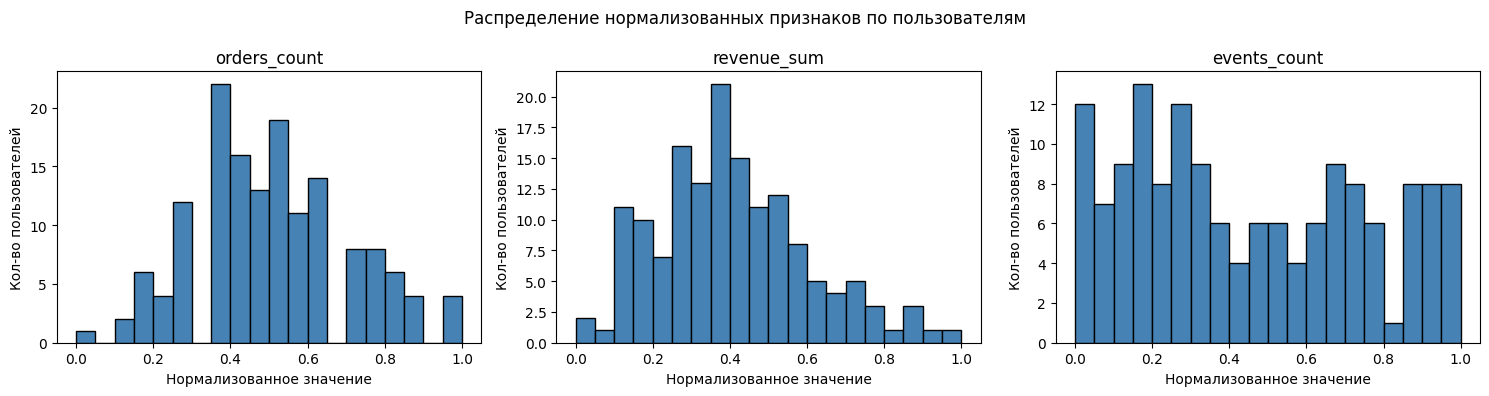

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["orders_count_norm", "revenue_sum_norm", "events_count_norm"]):
    ax.hist(user_stats_norm[col], bins=20, color="steelblue", edgecolor="black")
    ax.set_title(col.replace("_norm", ""))
    ax.set_xlabel("Нормализованное значение")
    ax.set_ylabel("Кол-во пользователей")

plt.suptitle("Распределение нормализованных признаков по пользователям")
plt.tight_layout()
plt.show()

In [8]:
leaders.to_csv("top_users_normalized.csv", index=False)
user_stats_norm.to_csv("user_stats_normalized.csv", index=False)
print("✅ Файлы сохранены:")
print("   top_users_normalized.csv")
print("   user_stats_normalized.csv")

✅ Файлы сохранены:
   top_users_normalized.csv
   user_stats_normalized.csv


## Вывод

### Что сделано
- Загружены три CSV с заказами и два JSON с событиями.
- По каждому `user_id` построены три агрегата:
  - `orders_count` — число уникальных заказов,
  - `revenue_sum` — суммарная выручка,
  - `events_count` — количество событий.
- Применена **мин–макс нормализация** — все три признака приведены
  к диапазону [0; 1].
- Для каждого нормализованного признака найден пользователь-лидер.
- Результаты сохранены в CSV.

### Наблюдение
- **Лидер по заказам** и **лидер по выручке** — часто **разные люди**.
  Пользователь с большим числом заказов может заказывать дешёвые товары,
  и наоборот — один крупный заказ даёт максимальную выручку.
- **Лидер по событиям** — обычно тот, кто активно просматривает каталог,
  но не обязательно покупает. Высокая `events_count` при низком
  `orders_count` — признак «смотрящего» пользователя.
- Распределение нормализованных признаков **сильно скошено вправо**:
  большинство пользователей имеют значения близко к 0, и лишь небольшая
  группа — близко к 1.

### Интерпретация
1. **Разные лидеры по разным признакам** — важный бизнес-сигнал:
   нельзя оценивать ценность клиента по одному показателю.
2. **Мин–макс нормализация** удобна для сравнения признаков с разными
   масштабами (заказы — единицы, выручка — тысячи, события — десятки),
   но она **чувствительна к выбросам**: один аномально большой заказ
   сжимает всех остальных к нулю.
3. **Пользователи с максимумом по событиям** — кандидаты на
   ретаргетинг: они интересуются товарами, но ещё не купили.

### Следствие для бизнеса
- **Сегментация.** По сочетанию трёх нормализованных признаков можно
  выделить группы: «покупатели», «наблюдатели», «активные», «спящие».
- **Маркетинг.** Лидеры по выручке — для программы лояльности;
  лидеры по событиям без покупок — для ретаргетинга.
- **Аналитика.** Нормализованные признаки удобны как вход для ML-моделей
  (кластеризация, прогноз оттока).

### Ограничения
- Данные **синтетические** — выводы демонстрационные.
- Мин–макс нормализация **не устойчива к выбросам**: один крупный заказ
  или один супер-активный пользователь сжимает распределение.
  Альтернатива — Z-нормализация (стандартизация) или робастное
  масштабирование.
- Агрегаты не учитывают **время**: активный вчера пользователь может
  быть «спящим» сегодня. Для учёта времени нужны оконные метрики
  (за последние 7/30 дней).
- `events_count` включает **все** события, в том числе технические.
  Для чистоты стоит фильтровать по `event_type`.
- Нулевые значения `orders_count` или `events_count` после join
  заменены на 0 — это осознанное решение, но оно может маскировать
  «новых» пользователей.